[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/okumura-kobe/kobe-data-business/blob/main/lecture03/lecture3_notebook.ipynb)

# 後期大学院演習「データで動かす社会とビジネス」
## 第3回　演習 Notebook

**テーマ：データを読み、比較する**
― 問いに答えるために、データを分けて見る ―

---

### この Notebook の使い方

- **STEP 1 はコードなし**：第2回のワークシートを手元に用意して、問いと設計表を確認してください
- **STEP 2〜4 でコードを実行**：`____` を自分の問いに合わせて埋めてください
- **STEP 5・6 はコードなし**：分析結果をワークシートに記録してください

**今日の核心**
> 比較の切り方で、見えるものが変わる。
> 全体 → 1軸比較 → 2軸比較 と深めていく。

---

| | |
|---|---|
| 学籍番号 | |
| 氏名 | |
| 実施日 | |

---
## Step 0　準備

In [1]:
# ライブラリの読み込み（変更不要）
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import urllib.request, zipfile, io, warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.2f}'.format)

matplotlib.rcParams['axes.spines.top']   = False
matplotlib.rcParams['axes.spines.right'] = False
matplotlib.rcParams['figure.figsize']    = (11, 4)

print('Ready')

Ready


In [2]:
# データの読み込み（変更不要）
url = "https://raw.githubusercontent.com/okumura-kobe/kobe-data-business/main/data/bike.csv"
df = pd.read_csv(url)

print(f'Rows: {df.shape[0]:,}  Cols: {df.shape[1]}')
df.head()

Rows: 17,379  Cols: 17


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1


---
## STEP 1　第2回の問いを再確認する

**コードなし。第2回のワークシートを参照してください。**

以下をこのセルのコメントに転記してください。

In [ ]:
# 第2回の設計表より転記する
#
# 【修正後の問い（②）】
#
#
# 【目的変数（③）】  例: 'cnt', 'registered', 'casual'
#
#
# 【比較・説明変数（④）】  例: 'workingday', 'weathersit', 'hr'
#
#
# 【判断基準（⑦）】
#
#
# 【今日の分析ストーリー】全体 → 1軸 → 2軸 と、どの順番で比較を深めるか
#
#


---
## STEP 2　1軸比較（最初の切り口）

まず1つの変数で比較します。
自分の比較変数（④）の中から最も重要だと思う1つを選んでください。

In [3]:
# 2-1　1軸比較：目的変数を1つの変数で集計する
# TODO: ③目的変数と④比較変数（1つ）を入れてください

result_1axis = df.groupby('hr')['cnt'].mean()
print('1軸比較の結果:')
print(result_1axis.round(2))

1軸比較の結果:
hr
0     53.90
1     33.38
2     22.87
3     11.73
4      6.35
5     19.89
6     76.04
7    212.06
8    359.01
9    219.31
10   173.67
11   208.14
12   253.32
13   253.66
14   240.95
15   251.23
16   311.98
17   461.45
18   425.51
19   311.52
20   226.03
21   172.31
22   131.34
23    87.83
Name: cnt, dtype: float64


In [4]:
# 2-2　比較の文脈を追加で確認する（必要に応じて）
# 件数（データのバランス）も確認しておく

count_1axis = df.groupby('hr').size()
print('グループ別件数:')
print(count_1axis)

グループ別件数:
hr
0     726
1     724
2     715
3     697
4     697
5     717
6     725
7     727
8     727
9     727
10    727
11    727
12    728
13    729
14    729
15    729
16    730
17    730
18    728
19    728
20    728
21    728
22    728
23    728
dtype: int64


---
## STEP 3　2軸比較（切り口を増やす）

STEP 2の比較に軸を1つ加えます。
同じデータでも、切り方を変えると何が変わるかを確認してください。

In [5]:
# 3-1　2軸比較：2つの変数でグループ化する
# TODO: 2つの比較変数を入れてください
# 例: df.groupby(['hr', 'workingday'])['cnt'].mean()

result_2axis = df.groupby(['hr', 'workingday'])['cnt'].mean()
print('2軸比較の結果:')
print(result_2axis.round(2))


2軸比較の結果:
hr  workingday
0   0             90.80
    1             36.79
1   0             69.51
    1             16.55
2   0             53.17
    1              8.68
3   0             25.78
    1              4.94
4   0              8.26
    1              5.43
5   0              8.69
    1             24.91
6   0             18.74
    1            102.50
7   0             43.41
    1            290.61
8   0            105.65
    1            477.01
9   0            171.62
    1            241.52
10  0            255.91
    1            135.37
11  0            315.32
    1            158.23
12  0            366.26
    1            200.82
13  0            372.73
    1            198.43
14  0            364.65
    1            183.57
15  0            358.81
    1            201.33
16  0            352.73
    1            293.12
17  0            323.55
    1            525.29
18  0            281.06
    1            492.23
19  0            231.67
    1            348.40
20  0           

In [ ]:
# 3-2【任意】ピボットテーブルで見やすく整理する
# TODO: index（行）、columns（列）、values（集計値）を入れてください
# 例: pd.pivot_table(df, index='hr', columns='workingday', values='cnt', aggfunc='mean')

pivot = pd.pivot_table(
    df,
    index=____,
    columns=____,
    values=____,
    aggfunc='mean'
)
print(pivot.round(1))

---
## STEP 4　可視化（問いに合ったグラフを選ぶ）

STEP 2または3の結果をグラフで確認します。
自分の問いに最も適切なグラフを選んでください。

**選択肢：**
- 棒グラフ：グループ間の大小を比較するとき
- 折れ線グラフ：時間帯など連続的な変化を見るとき
- 箱ひげ図：分布のばらつきを見るとき

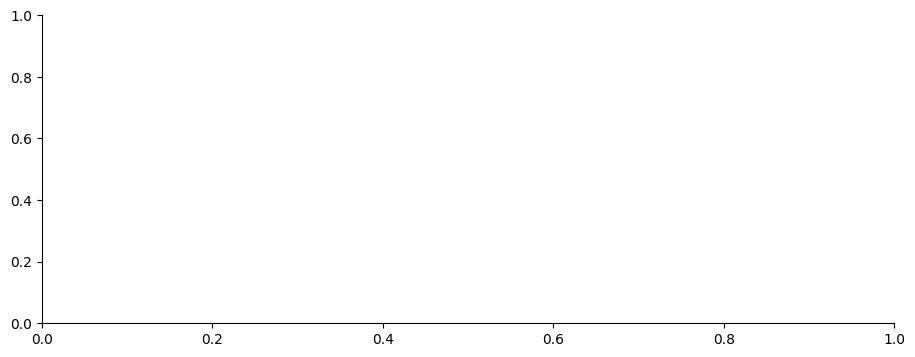

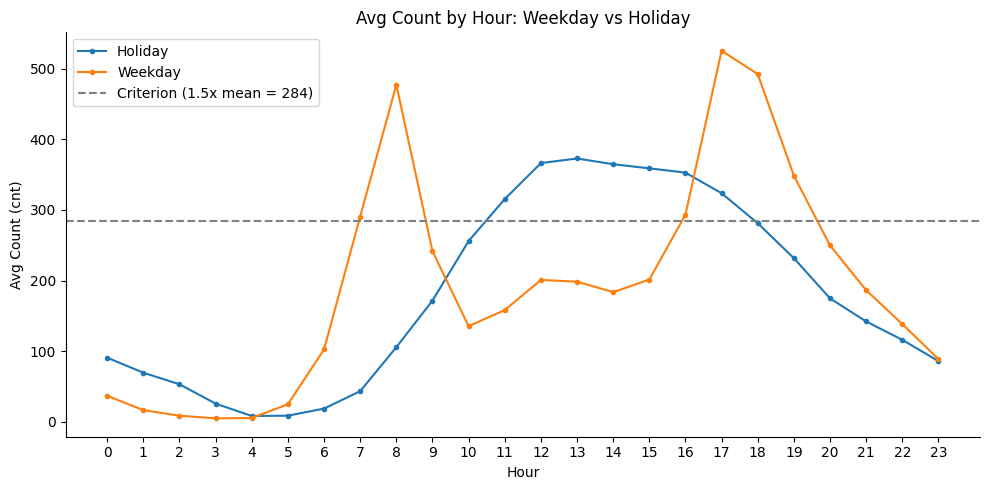

In [6]:
# 4-1　可視化する
# TODO: 自分の問いに合ったグラフを作成してください

fig, ax = plt.subplots()

# ── 棒グラフの例 ──────────────────────────────────────────────────────
# result_1axis.plot(kind='bar', ax=ax, color='#1E2761', alpha=0.85)

# ── 折れ線グラフの例（時間帯×グループ）──────────────────────────────
# for group_val in df[____].unique():
#     subset = df[df[____] == group_val].groupby(____)[____].mean()
#     ax.plot(subset.index, subset.values, label=str(group_val), marker='o', markersize=3)
# ax.legend()

# ── 自分のコードをここに書く ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
labels = {0: 'Holiday', 1: 'Weekday'}
for group_val in sorted(df['workingday'].unique()):
    subset = df[df['workingday'] == group_val].groupby('hr')['cnt'].mean()
    ax.plot(subset.index, subset.values, label=labels[group_val], marker='o', markersize=3)

criterion = df['cnt'].mean() * 1.5
ax.axhline(criterion, color='gray', linestyle='--', label=f'Criterion (1.5x mean = {criterion:.0f})')

ax.set_xticks(range(24))
ax.legend()

ax.set_title('Avg Count by Hour: Weekday vs Holiday')
ax.set_xlabel('Hour')
ax.set_ylabel('Avg Count (cnt)')
plt.tight_layout()
plt.show()


---
## STEP 5　判断基準に照らした示唆

**コードなし。ワークシートの STEP 5 に記入してください。**

以下をコメントとして記録してください。

In [ ]:
# STEP 5：判断基準に照らした示唆を記録する
#
# 【第2回の判断基準（⑦）を転記】
#
#
# 【今日の分析から言える示唆】
# 判断基準に照らして、今日の結果はどう解釈できるか？
# 意思決定課題に対して何が言えるか？
#
#


---
## STEP 6　言えること・言えないこと

**コードなし。ワークシートの STEP 6 に記入してください。**

In [ ]:
# STEP 6：言えること・言えないことを記録する
#
# 【今日の分析から「言えること」】
# 観測されたパターン・傾向
#
#
# 【今日の分析では「言えないこと」】
# 相関 ≠ 因果。施策効果を言うには何が必要か？
#
#
# 【観測と因果の区別】
# 今日見えたパターンは「相関」か「因果」か？
#
#


---
## まとめ

### 今日学んだこと

| STEP | 内容 |
|---|---|
| STEP 1 | 第2回の問い・設計表を起点に比較を設計した |
| STEP 2 | 1軸比較で最初の切り口を確認した |
| STEP 3 | 2軸比較で見えなかった構造を発見した |
| STEP 4 | 問いに合ったグラフで可視化した |
| STEP 5 | 判断基準に照らして示唆を整理した |
| STEP 6 | 「言えること」と「言えないこと」を区別した |

### 今日の核心

> **比較の切り方で、見えるものが変わる。**
> 全体だけ見ていると見えない構造が、軸を増やすことで浮かび上がる。
> しかし観測パターンから施策効果（因果）は言えない。それは第5〜9回へ。

---

### 次回（第4回）：分析できるデータを作る

**事前課題**
- 今日の分析で「こう比較したかった」と思ったことをメモしておく
- BEEF+ の第4回配布資料を読む
- 今日のグラフ・集計結果を保存しておく（課題提出に使用）